In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq
from astroquery.vizier import Vizier

## Model Parameters

In [2]:
# Reproducibility
seed = 42                      # seed for all random numbers
rng = np.random.default_rng(seed)
N = 10**6                      # number of objects in the main simulation

# Kroupa (2001) IMF
mass_ranges = np.array([0.01, 0.08, 0.5, 100])   # Msun, break masses
alphas = np.array([0.3, 1.3, 2.3])               # slope of each segment

# Star formation and main sequence
T_MW = 10.0        # Gyr, age of the Galaxy
T_MS_SUN = 10.0    # Gyr, MS lifetime of a 1 Msun star
MS_EXP = -2.5      # t_MS = T_MS_SUN * M**MS_EXP
M_H_BURN = 0.08    # Msun, below this: brown dwarf

# Remnants
M_WD_MAX = 9.0           # Msun, below: WD (Miller+26); above: NS or BH (Raithel+18)
F_EJ = 0.9               # fraction of the envelope ejected when a BH forms
M_BH_BRANCH_II = 45.0    # Msun, start of BH Branch II
R_NS_KM = 12.0           # km, NS radius (Raithel+18)
GM_SUN_C2_KM = 1.4766    # km, G Msun / c^2
# Raithel+18, Table 3: P(NS) in [NS_EDGES[i], NS_EDGES[i+1]); P = 0 -> always BH
NS_EDGES = np.array([9.0, 13.0, 15.0, 17.8, 18.5, 21.7, 25.2, 27.5, 60.0, 120.0])
NS_PROB  = np.array([1.00, 1.00, 0.679, 0.833, 0.500, 0.0, 0.652, 0.0, 0.400])

# Closed box
Z_SUN = 0.014                       # solar metallicity
MU_F = 0.1                          # final (present-day) gas fraction
Y_EFF = Z_SUN / np.log(1 / MU_F)    # effective yield: Z(T_MW) = Z_SUN
MH_FLOOR = -3.0                     # [M/H] floor for Z = 0
MH_CUT = -0.5                       # metal-poor threshold

# G dwarfs and MDF
G_MIN = 0.8        # Msun
G_MAX = 1.05       # Msun
DBIN = 0.1         # dex, MDF bin width

# Infall
Z_IN = 0.0                # metallicity of the infalling gas (pristine)
TAU_INFALL = [1.0,3.0,5.0,7.0,9.0]   # Gyr, infall timescales to compare
M_GAS0 = 0.0              # initial gas mass (in units of the final total mass)
STEP = 5000               # time steps of the Euler integration

# Convergence
N_CONV = np.unique(np.logspace(2, 6, 9).astype(int))   
N_SEEDS = 10                                           

## Part 1: Kroupa IMF

In [3]:
k = np.ones(len(alphas))
for i in range(1, len(alphas)):
    k[i] = k[i-1] * mass_ranges[i]**(alphas[i] - alphas[i-1])

def kroupa_imf(m):
    """
    Unnormalized Kroupa IMF, continuous at the break masses.
    Input:  m, mass in Msun (scalar or array)
    Output: xi, zero outside [mass_ranges[0], mass_ranges[-1]]
    """
    m = np.asarray(m, dtype=float)
    xi = np.zeros_like(m)
    for i in range(len(alphas)):
        in_range = (m >= mass_ranges[i]) & (m < mass_ranges[i + 1])
        xi[in_range] = k[i] * m[in_range]**(-alphas[i])
    xi[m == mass_ranges[-1]] = k[-1] * mass_ranges[-1]**(-alphas[-1])
    return xi

In [4]:
# Normalization: w_i = integral of the IMF over each segment, a = 1 / sum(w_i)
# P_i = a w_i is the probability of each segment and f_breaks the CDF at the breaks

p = 1 - alphas                                            # exponent of the integral
w = k * (mass_ranges[1:]**p - mass_ranges[:-1]**p) / p    # integral of the IMF in each segment
a = 1 / w.sum()                                           # normalization constant
f_breaks = np.concatenate(([0], np.cumsum(w) * a))        # CDF at each break

print("P per segment:", w * a)
print("F at breaks:  ", f_breaks)

P per segment: [0.37148817 0.47811341 0.15039842]
F at breaks:   [0.         0.37148817 0.84960158 1.        ]


In [5]:
def sample_kroupa(n, rng):
    """
    Draws initial masses from the Kroupa IMF (piecewise inverse transform sampling).
    With u ~ U(0,1): find the segment i of u and solve
    M = [m_i^p_i + p_i (u - F(m_i)) / (a k_i)]^(1/p_i)
    Inputs: n, number of stars; rng, np.random.Generator
    Output: array (n,) of masses in Msun
    """
    u = rng.uniform(size=n)
    i = np.searchsorted(f_breaks, u, side='right') - 1    # segment of each u
    pi = p[i]
    return (mass_ranges[i]**pi + pi * (u - f_breaks[i]) / (a * k[i]))**(1 / pi)

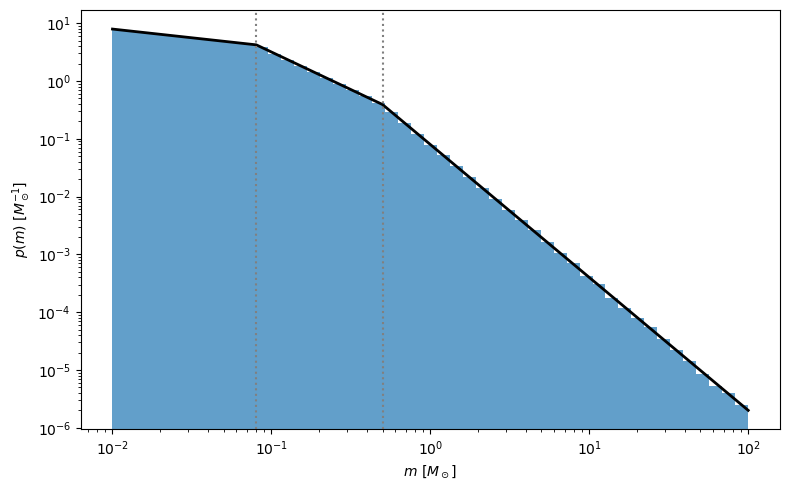

In [6]:
M = sample_kroupa(N, rng)

bins = np.logspace(np.log10(mass_ranges[0]), np.log10(mass_ranges[-1]), 50)

plt.figure(figsize=(8, 5))
plt.hist(M, bins=bins, density=True, alpha=0.7, label=f'N = {N:.0e}' )
m_plot = np.logspace(np.log10(mass_ranges[0]), np.log10(mass_ranges[-1]), 1000)
plt.plot(m_plot, a * kroupa_imf(m_plot), 'k-', lw=2, label='Kroupa (2001)')

for mb in mass_ranges[1:-1]:
    plt.axvline(mb, ls=':', c='gray')

plt.xscale('log')
plt.yscale('log')

plt.xlabel(r"$m\ [M_\odot]$")
plt.ylabel(r"$p(m)\ [M_\odot^{-1}]$")

plt.tight_layout()
plt.savefig("figs/imf_kroupa.png", dpi=150)
plt.show()

In [7]:
# Validation: fraction of the sample in each segment vs theoretical probability P_i,
# with expected binomial error sqrt(P (1 - P) / N)
print("Minimum mass:", M.min())
print("Maximum mass:", M.max())
print("Number of objects:", len(M))

print("\n    Segment       Theory    Sample    Error")
for i in range(len(alphas)):
    lower = mass_ranges[i]
    higher = mass_ranges[i+1]
    frac = np.mean((M >= lower) & (M < higher))
    err = np.sqrt(w[i]*a * (1 - w[i]*a) / len(M))

    print(f"{lower:5.2f} – {higher:6.2f}   {w[i]*a:.4f}    {frac:.4f}    ± {err:.4f}")

Minimum mass: 0.010000015801212911
Maximum mass: 99.85859125980448
Number of objects: 1000000

    Segment       Theory    Sample    Error
 0.01 –   0.08   0.3715    0.3712    ± 0.0005
 0.08 –   0.50   0.4781    0.4784    ± 0.0005
 0.50 – 100.00   0.1504    0.1503    ± 0.0004


### Part 2: Star Formation and Main Sequence

In [8]:
def sample_birth_times(n, rng):
    """
    Birth times for a constant SFR: t_birth ~ U(0, T_MW).
    Inputs: n, number of stars; rng, np.random.Generator
    Output: array (n,) in Gyr, measured from the formation of the Galaxy
    """
    return rng.uniform(0.0, T_MW, size=n)

def ms_lifetime(M):
    """
    Main-sequence lifetime, t_MS = T_MS_SUN * M**MS_EXP.
    Input:  M, mass(es) in Msun
    Output: t_MS in Gyr
    """
    return T_MS_SUN * np.asarray(M, dtype=float)**MS_EXP

In [9]:
birth_times = sample_birth_times(N, rng)
print(f"mean: {birth_times.mean():.4f}   (theory: {T_MW/2:.4f})")
print(f"std:  {birth_times.std():.4f}   (theory: {T_MW/np.sqrt(12):.4f})")

mean: 4.9982   (theory: 5.0000)
std:  2.8858   (theory: 2.8868)


In [10]:
# Classification: brown dwarf (BD), main sequence (MS) or evolved
t_age = T_MW - birth_times
t_MS = ms_lifetime(M)

is_BD = M < M_H_BURN                           # brown dwarfs
is_evolved = (M >= M_H_BURN) & (t_age > t_MS)  # already left the MS
is_MS = (M >= M_H_BURN) & (t_age <= t_MS)      # still on the MS

n_stars = np.sum(M >= M_H_BURN)                # stars (BDs excluded)

print(f"Brown dwarfs: {is_BD.mean():.4f} of all objects")
print(f"MS:           {is_MS.sum()/n_stars:.4f} of stars")
print(f"Evolved:      {is_evolved.sum()/n_stars:.4f} of stars")
print(f"Minimum evolved mass: {M[is_evolved].min():.3f} Msun")

Brown dwarfs: 0.3712 of all objects
MS:           0.9361 of stars
Evolved:      0.0639 of stars
Minimum evolved mass: 1.002 Msun


## Part 3: Stellar Remnants

In [11]:
BD, MS, WD, NS, BH = 0, 1, 2, 3, 4
TYPE_NAMES = {BD: "BD", MS: "MS", WD: "WD", NS: "NS", BH: "BH"}

In [12]:
def wd_mass_miller(Mi):
    """
    White dwarf final mass, Miller et al. (2026)
    Input:  Mi, initial mass(es) in Msun. Above 8.39 Msun the last segment is
            extrapolated up to M_WD_MAX.
    Output: M_WD in Msun
    """
    Mi = np.asarray(Mi, dtype=float)
    conditions = [Mi < 1.98, Mi < 2.33, Mi < 3.98]
    values = [0.160 * Mi + 0.394,      # 0.84 <= Mi < 1.98
              -0.155 * Mi + 1.015,     # 1.98 <= Mi < 2.33
              0.174 * Mi + 0.251]      # 2.33 <= Mi < 3.98
    return np.select(conditions, values, default=0.075 * Mi + 0.644)   # 3.98 <= Mi < 9

In [13]:
def ns_probability(Mi):
    """
    Probability that a star with Mi >= 9 Msun forms a NS Raithel+18
    Input:  Mi in Msun
    Output: P(NS) of the NS_EDGES interval containing Mi (P(BH) = 1 - P(NS))
    """
    Mi = np.asarray(Mi, dtype=float)
    i = np.clip(np.searchsorted(NS_EDGES, Mi, side="right") - 1, 0, len(NS_PROB) - 1)
    return NS_PROB[i]

In [14]:
def ns_baryonic_mass(Mi, rng):
    """
    NS baryonic mass for each branch of Raithel+18
    Inputs: Mi in Msun (stars that form a NS), rng for the Gaussian branches
    Output: M_NS,b in Msun
    """
    Mi = np.asarray(Mi, dtype=float)
    x1 = Mi - 14.75
    x6 = Mi - 2.619
    gauss_V = rng.normal(1.60, 0.158, size=Mi.shape)
    gauss_VII = rng.normal(1.78, 0.02, size=Mi.shape)
    conditions = [Mi < 13.0, Mi < 15.0, Mi < 17.8, Mi < 18.5, Mi < 21.7, Mi < 27.5]
    values = [
        2.24 + 0.508 * x1 + 0.125 * x1**2 + 0.0110 * x1**3,          # I   (9 - 13)
        0.123 + 0.112 * Mi,                                           # II  (13 - 15)
        0.996 + 0.0384 * Mi,                                          # III (15 - 17.8)
        -0.020 + 0.10 * Mi,                                           # IV  (17.8 - 18.5)
        gauss_V,                                                      # V   (18.5 - 21.7)
        3232.29 - 409.429 * x6 + 17.2867 * x6**2 - 0.24315 * x6**3,  # VI  (25.2 - 27.5)
    ]
    return np.select(conditions, values, default=gauss_VII)          # VII (60 - 120)


def ns_gravitational_mass(Mb, R_km=R_NS_KM, n_iter=50):
    """
    Converts baryonic to gravitational mass Raithel+18
    Mb = Mg + BE, BE = Mg * 0.6 beta / (1 - 0.5 beta), beta = G Mg / (R c^2).
    Since Mg appears on both sides, it is solved by fixed-point iteration.
    Inputs: Mb in Msun; R_km NS radius in km; n_iter iterations
    Output: Mg in Msun
    """
    Mb = np.asarray(Mb, dtype=float)
    Mg = Mb.copy()
    for _ in range(n_iter):
        beta = GM_SUN_C2_KM * Mg / R_km
        Mg = Mb / (1.0 + 0.6 * beta / (1.0 - 0.5 * beta))
    return Mg


def bh_mass_raithel(Mi, f_ej=F_EJ):
    """
    Black hole mass, Raithel+18 
    Branch I  (Mi < M_BH_BRANCH_II): M = f_ej * M_core + (1 - f_ej) * M_all
    Branch II (Mi >= M_BH_BRANCH_II): M = 5.697 + 7.8598e8 Mi^-4.858
    Inputs: Mi in Msun; f_ej ejected fraction of the envelope
    Output: M_BH in Msun
    """
    Mi = np.asarray(Mi, dtype=float)
    x = Mi - 25.97
    M_core = -2.049 + 0.4140 * Mi                                     # only the He core collapses
    M_all = 15.52 - 0.3294 * x - 0.02121 * x**2 + 0.003120 * x**3     # the whole star collapses
    M_branch_I = f_ej * M_core + (1.0 - f_ej) * M_all
    M_branch_II = 5.697 + 7.8598e8 * Mi**(-4.858)                     # the CO core collapses
    return np.where(Mi < M_BH_BRANCH_II, M_branch_I, M_branch_II)

In [15]:
def remnant_from_mass(Mi, rng):
    """
    Remnant type and mass of stars that have left the MS.
    M < M_WD_MAX -> WD. Otherwise NS (probability P(NS)) or BH (1 - P(NS)) is drawn at random.
    Inputs: Mi, initial masses in Msun; rng, np.random.Generator
    Output: (rtype, M_final): rtype with codes WD/NS/BH and M_final in Msun
    """
    Mi = np.asarray(Mi, dtype=float)
    rtype = np.full(Mi.shape, WD)
    M_final = np.zeros_like(Mi)

    is_wd = Mi < M_WD_MAX
    M_final[is_wd] = wd_mass_miller(Mi[is_wd])

    u = rng.uniform(size=Mi.shape)                 # NS vs BH draw
    is_ns = ~is_wd & (u < ns_probability(Mi))
    is_bh = ~is_wd & ~is_ns

    M_final[is_ns] = ns_gravitational_mass(ns_baryonic_mass(Mi[is_ns], rng))
    M_final[is_bh] = bh_mass_raithel(Mi[is_bh])
    rtype[is_ns] = NS
    rtype[is_bh] = BH
    return rtype, M_final


def classify_population(M, t_age, rng):
    """
    Classifies each object as BD, MS, WD, NS or BH and assigns its present-day mass.
    Inputs: M initial masses [Msun]; t_age ages [Gyr]; rng, np.random.Generator
    Output: (star_type, M_final) arrays with the same length as M
    """
    star_type = np.full(M.shape, MS)
    M_final = M.copy()                    # MS stars and BDs keep their mass
    star_type[M < M_H_BURN] = BD
    evol = (M >= M_H_BURN) & (t_age > ms_lifetime(M))
    star_type[evol], M_final[evol] = remnant_from_mass(M[evol], rng)
    return star_type, M_final

In [16]:
# Check of the relations at known masses
print("WD (Miller+26):  M_i = 1, 2, 4, 8, 9  ->", np.round(wd_mass_miller([1, 2, 4, 8, 9]), 3))
print("NS baryonic -> gravitational, 1.6 Msun ->", np.round(ns_gravitational_mass(1.6), 3))
print("BH (Raithel+18): M_i = 20, 30, 44.9, 45, 60, 100 ->",
      np.round(bh_mass_raithel([20, 30, 44.9, 45, 60, 100]), 2))

WD (Miller+26):  M_i = 1, 2, 4, 8, 9  -> [0.554 0.705 0.944 1.244 1.319]
NS baryonic -> gravitational, 1.6 Msun -> 1.434
BH (Raithel+18): M_i = 20, 30, 44.9, 45, 60, 100 -> [ 7.21 10.74 17.17 13.01  7.5   5.85]


In [17]:
# Classification of the whole population (must run after birth_times because it uses rng)
star_type, M_final = classify_population(M, t_age, rng)

print(f"Evolved stars: {is_evolved.sum()} out of {n_stars} stars\n")
print(f"{'Type':<5}{'N':>9}{'fraction':>11}{'<M_i>':>9}{'<M_f>':>9}{'<age>':>9}")
for c in [MS, WD, NS, BH]:
    sel = star_type == c
    print(f"{TYPE_NAMES[c]:<5}{sel.sum():>9}{sel.sum()/n_stars:>11.5f}"
          f"{M[sel].mean():>9.2f}{M_final[sel].mean():>9.2f}{t_age[sel].mean():>9.2f}")
print(f"\nBD: {np.sum(star_type == BD)} objects ({np.mean(star_type == BD):.4f} of all objects)")

Evolved stars: 40204 out of 628762 stars

Type         N   fraction    <M_i>    <M_f>    <age>
MS      588558    0.93606     0.32     0.32     4.93
WD       36860    0.05862     2.72     0.75     6.12
NS        2213    0.00352    14.44     1.41     4.94
BH        1131    0.00180    34.04     9.50     5.02

BD: 371238 objects (0.3712 of all objects)


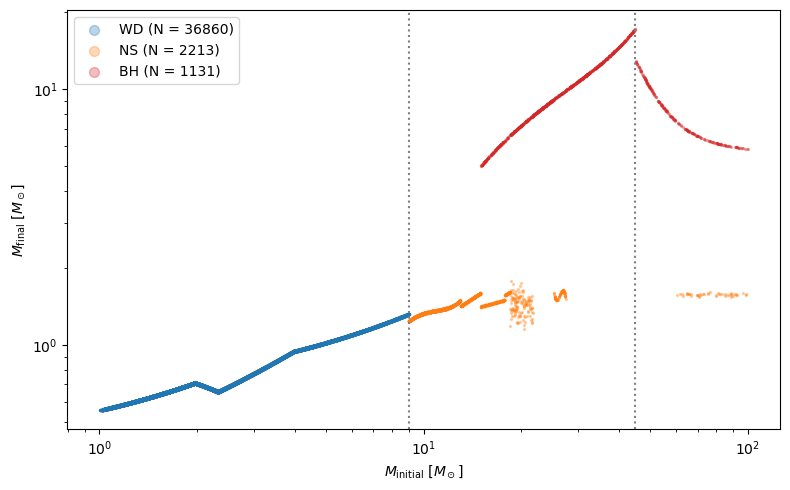

In [18]:
# Initial-final mass relation of the evolved stars
fig, ax = plt.subplots(figsize=(8, 5))
colors = {WD: "C0", NS: "C1", BH: "C3"}
for c in [WD, NS, BH]:
    sel = star_type == c
    ax.scatter(M[sel], M_final[sel], s=2, alpha=0.3, color=colors[c],
               label=f"{TYPE_NAMES[c]} (N = {sel.sum()})")

ax.axvline(M_WD_MAX, ls=":", c="gray")
ax.axvline(M_BH_BRANCH_II, ls=":", c="gray")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel(r"$M_{\rm initial}\ [M_\odot]$")
ax.set_ylabel(r"$M_{\rm final}\ [M_\odot]$")
ax.legend(markerscale=5)
fig.tight_layout()
fig.savefig("figs/initial_final_mass.png", dpi=150)
plt.show()

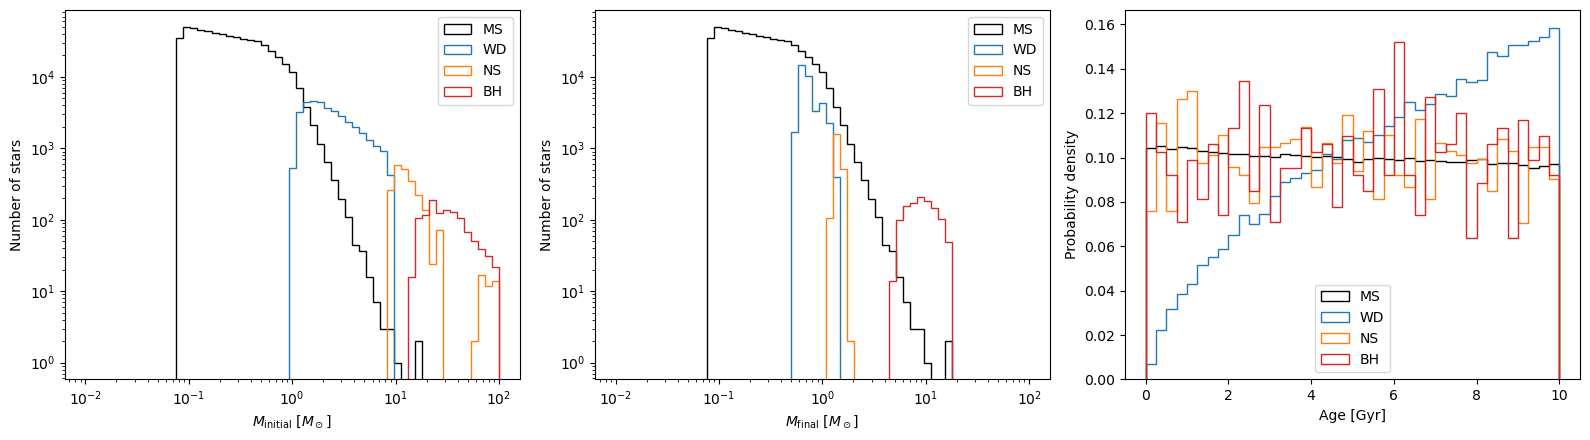

In [19]:
# Distributions of initial mass, final mass and age for each type
bins_m = np.logspace(-2, 2, 60)
bins_age = np.linspace(0, T_MW, 41)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for c, col in zip([MS, WD, NS, BH], ["k", "C0", "C1", "C3"]):
    sel = star_type == c
    axes[0].hist(M[sel], bins=bins_m, histtype="step", lw=1.5, color=col, label=TYPE_NAMES[c])
    axes[1].hist(M_final[sel], bins=bins_m, histtype="step", lw=1.5, color=col, label=TYPE_NAMES[c])
    axes[2].hist(t_age[sel], bins=bins_age, histtype="step", lw=1.5, color=col,
                 density=True, label=TYPE_NAMES[c])

for ax in axes[:2]:
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_ylabel("Number of stars")
axes[0].set_xlabel(r"$M_{\rm initial}\ [M_\odot]$")
axes[1].set_xlabel(r"$M_{\rm final}\ [M_\odot]$")
axes[2].set_xlabel("Age [Gyr]")
axes[2].set_ylabel("Probability density")
for ax in axes:
    ax.legend()
fig.tight_layout()
fig.savefig("figs/distributions_by_type.png", dpi=150)
plt.show()

### Part 4: Closed Box Model

In [20]:
def gas_fraction(t):
    """
    Gas fraction of the closed box with constant SFR.
    Input:  t, time(s) since the formation of the Galaxy [Gyr]
    Output: mu(t) = 1 - (1 - MU_F) t / T_MW   (mu(0) = 1, mu(T_MW) = MU_F)
    """
    t = np.asarray(t, dtype=float)
    return 1.0 - (1.0 - MU_F) * t / T_MW

def closed_box(t):
    """
    Gas metallicity in the closed box model.
    Input:  t, time(s) since the formation of the Galaxy [Gyr]
    Output: Z(t) = Y_EFF * ln(1 / mu(t)); equals Z_SUN at t = T_MW
    """
    return Y_EFF * np.log(1.0 / gas_fraction(t))

def Z_to_MH(Z):
    """
    Converts Z to [M/H] = log10(Z / Z_SUN).
    Input:  Z, scalar or array (Z = 0 is allowed)
    Output: [M/H]; values below MH_FLOOR (including Z = 0 -> -inf) are set to MH_FLOOR
    """
    Z = np.asarray(Z, dtype=float)
    with np.errstate(divide="ignore"):
        MH = np.log10(Z / Z_SUN)
    return np.maximum(MH, MH_FLOOR)

In [21]:
Z_birth = closed_box(birth_times)   # evaluated at t_birth, not at t_age
MH = Z_to_MH(Z_birth)

# Validation with the analytic prediction: F(Z_c) = (1 - exp(-Z_c / Y_EFF)) / (1 - MU_F)
Z_CUT = Z_SUN * 10**MH_CUT
frac_theory = (1 - np.exp(-Z_CUT / Y_EFF)) / (1 - MU_F)
frac_sim = np.mean(MH < MH_CUT)

print(f"[M/H] range: {MH.min():.2f} to {MH.max():.3f}")
print(f"Fraction at the floor (MH = {MH_FLOOR}): {np.mean(MH == MH_FLOOR):.4f}")
print(f"Fraction with [M/H] < {MH_CUT}: simulated {frac_sim:.4f}  |  analytic {frac_theory:.4f}")

[M/H] range: -3.00 to -0.000
Fraction at the floor (MH = -3.0): 0.0025
Fraction with [M/H] < -0.5: simulated 0.5751  |  analytic 0.5747


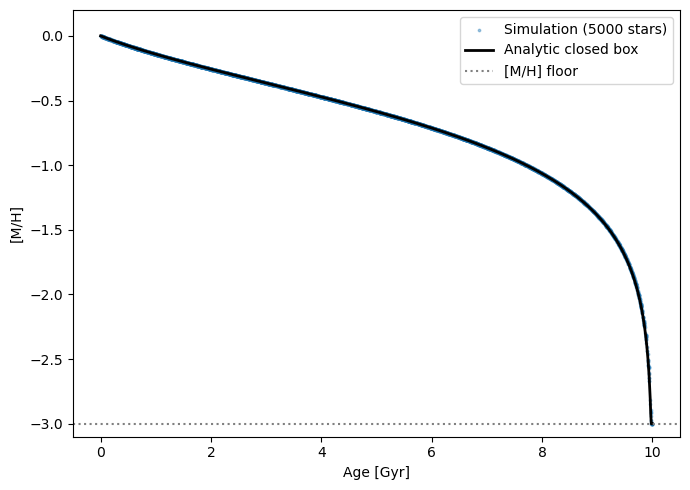

In [22]:
# Age-metallicity relation (subsample of 5000 stars so the scatter is readable)
n_show = 5000
idx = np.arange(n_show)

t_grid = np.linspace(1e-4, T_MW, 1000)          # t_birth
MH_theory = Z_to_MH(closed_box(t_grid))

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(t_age[idx], MH[idx], s=3, alpha=0.4, label=f"Simulation ({n_show} stars)")
ax.plot(T_MW - t_grid, MH_theory, "k-", lw=2, label="Analytic closed box")
ax.axhline(MH_FLOOR, ls=":", c="gray", label="[M/H] floor")
ax.set_xlabel("Age [Gyr]")
ax.set_ylabel("[M/H]")
ax.set_ylim(MH_FLOOR - 0.1, 0.2)
ax.legend()
fig.tight_layout()
fig.savefig("figs/age_metallicity_closedbox.png", dpi=150)
plt.show()

### Part 5: Observations

In [23]:
vizier_hay = Vizier(
    columns=["HIP", "[Fe/H]", "ST"],
    row_limit=-1
) 
vizier_gcs = Vizier(
    columns=["HIP", "[Fe/H]"],
    row_limit=-1
)

hay = vizier_hay.get_catalogs("J/MNRAS/325/1365/table3")[0]
gcs = vizier_gcs.get_catalogs("V/130/gcs3")[0]

print(len(hay), len(gcs))

348 16682


In [24]:
seleccion = np.array(hay["ST"].filled(""), dtype=str) == "*"

hay_long = hay[seleccion]

feh_hay = np.array(hay_long["[Fe/H]"].filled(np.nan), dtype=float)
feh_hay = feh_hay[np.isfinite(feh_hay)]


feh_gcs = np.array(gcs["[Fe/H]"].filled(np.nan), dtype=float)
feh_gcs = feh_gcs[np.isfinite(feh_gcs)]

print("Valid [Fe/H]:", len(feh_hay))
print("Valid [Fe/H]:", len(feh_gcs))


Valid [Fe/H]: 218
Valid [Fe/H]: 16394


### Part 6 G-Dwarf Problem

In [25]:
def mdf(values, bins):
    """
    MDF normalized by the total size of the sample.
    Inputs: values, [Fe/H] or [M/H]; bins, bin edges
    Output: (pdf, Poisson error, N_tot)
    """
    values = np.asarray(values)
    counts, _ = np.histogram(values, bins=bins)
    n_tot = len(values)
    width = np.diff(bins)

    pdf = counts / (n_tot * width)
    error = np.sqrt(counts) / (n_tot * width)

    return pdf, error, n_tot


def frac_below(values, cut):
    """Fraction of values below the threshold cut."""
    values = np.asarray(values)
    return np.mean(values < cut)


def binomial_error(values, cut):
    """Binomial error sqrt(f (1 - f) / N) of the fraction below the threshold."""
    f = frac_below(values, cut)
    return np.sqrt(f * (1 - f) / len(values))

is_G = is_MS & (M > G_MIN) & (M < G_MAX)
MH_G = MH[is_G]
n_G = is_G.sum()

print("Model G dwarfs:", n_G)

Model G dwarfs: 24003


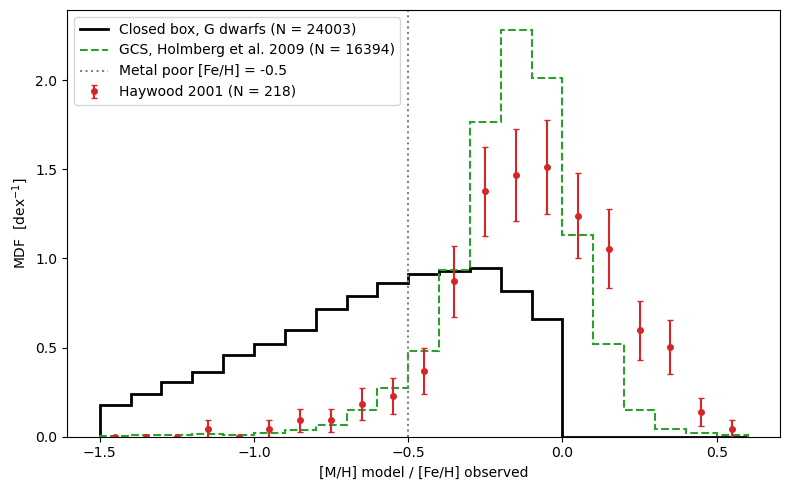

In [26]:
bins_feh = np.arange(-1.5, 0.6 + DBIN / 2, DBIN)
centers = 0.5 * (bins_feh[1:] + bins_feh[:-1])

pdf_mod, err_mod, n_mod = mdf(MH_G, bins_feh)
pdf_hay, err_hay, n_hay = mdf(feh_hay, bins_feh)
pdf_gcs, err_gcs, n_gcs = mdf(feh_gcs, bins_feh)

fig, ax = plt.subplots(figsize=(8, 5))
ax.stairs(pdf_mod, bins_feh, lw=2, color="k", label=f"Closed box, G dwarfs (N = {n_mod})")
ax.stairs(pdf_gcs, bins_feh, lw=1.5, ls="--", color="C2", label=f"GCS, Holmberg et al. 2009 (N = {n_gcs})")
ax.errorbar(centers, pdf_hay, yerr=err_hay, fmt="o", ms=4, color="C3", capsize=2,
            label=f"Haywood 2001 (N = {n_hay})")
ax.axvline(MH_CUT, ls=":", c="gray", label=f"Metal poor [Fe/H] = {MH_CUT}")
ax.set_xlabel("[M/H] model / [Fe/H] observed")
ax.set_ylabel(r"MDF  [dex$^{-1}$]")
ax.legend()
fig.tight_layout()
fig.savefig("figs/mdf_closedbox_vs_obs.png", dpi=150)
plt.show()

In [27]:
# Metal-poor fraction (± binomial error) and MDF peak (most populated bin)
print(f"{'Sample':<10}{'N':>7}   {'f([Fe/H] < -0.5)':<20}{'Peak':>6}")

for name, vals, pdf in [
    ("Model", MH_G, pdf_mod),
    ("Haywood", feh_hay, pdf_hay),
    ("GCS", feh_gcs, pdf_gcs),
]:
    f = frac_below(vals, MH_CUT)
    ef = binomial_error(vals, MH_CUT)
    peak = centers[np.argmax(pdf)]
    print(f"{name:<10}{len(vals):>7}   {f:.3f} ± {ef:.3f}     {peak:>6.2f}")

Sample          N   f([Fe/H] < -0.5)      Peak
Model       24003   0.573 ± 0.003      -0.25
Haywood       218   0.069 ± 0.017      -0.05
GCS         16394   0.060 ± 0.002      -0.15


### Part 7: Infall Model

In [28]:
def integrate_infall(tau, nu, Mg0=M_GAS0, y_eff=1.0, n_steps=STEP):
    """
    Integrates (explicit Euler) the one-zone model with exponential infall and instantaneous recycling.
    With Mg0 = 1, A0 = 0 (no infall).
    Inputs: tau [Gyr], nu [1/Gyr], Mg0, y_eff, n_steps
    Output: dict with arrays t, A, M_gas, M_star, M_Z, Z, psi, mu and the scalar A0
    """
    t = np.linspace(0.0, T_MW, n_steps + 1)
    dt = t[1] - t[0]
    A0 = (1.0 - Mg0) / (tau * (1.0 - np.exp(-T_MW / tau)))
    A = A0 * np.exp(-t / tau)

    M_gas = np.zeros_like(t)
    M_Z = np.zeros_like(t)
    M_star = np.zeros_like(t)
    M_gas[0] = Mg0

    for i in range(n_steps):
        psi_i = nu * M_gas[i]
        Z_i = M_Z[i] / M_gas[i] if M_gas[i] > 0 else 0.0
        M_gas[i + 1]  = M_gas[i]  + (A[i] - psi_i) * dt
        M_Z[i + 1]    = M_Z[i]    + (y_eff * psi_i - Z_i * psi_i + Z_IN * A[i]) * dt
        M_star[i + 1] = M_star[i] + psi_i * dt

    psi = nu * M_gas
    Z = np.divide(M_Z, M_gas, out=np.zeros_like(M_Z), where=M_gas > 0)
    M_tot = M_gas + M_star
    mu = np.divide(M_gas, M_tot, out=np.ones_like(M_gas), where=M_tot > 0)
    return dict(t=t, A=A, A0=A0, M_gas=M_gas, M_star=M_star, M_Z=M_Z, Z=Z, psi=psi, mu=mu)


def build_infall_model(tau, Mg0=M_GAS0):
    """
    Builds the infall model calibrated like the closed box:
      - nu such that mu(T_MW) = MU_F   (root found with brentq)
      - y_eff such that Z_gas(T_MW) = Z_SUN   (Z is proportional to y_eff because Z_IN = 0)
    Inputs: tau [Gyr], Mg0 initial gas
    Output: dict from integrate_infall + nu, y_eff, tau
    """
    # Find nu that reproduces the final gas fraction
    def mu_final(nu):
        model = integrate_infall(tau, nu, Mg0)
        return model["mu"][-1] - MU_F

    nu = brentq(mu_final, 1e-3, 20.0)

    # Find y_eff that reproduces the solar metallicity
    model = integrate_infall(tau, nu, Mg0, y_eff=1.0)
    y_eff = Z_SUN / model["Z"][-1]          # calibrated yield of this model
    model["Z"] *= y_eff
    model["M_Z"] *= y_eff

    # Store the parameters
    model.update(nu=nu, y_eff=y_eff, tau=tau)
    return model

In [29]:
def check_model(name, m):
    """Prints the calibration (mu_f, Z_f) and mass conservation of a model."""
    M_final = m["M_gas"][-1] + m["M_star"][-1]
    print(f"{name:<22} nu = {m['nu']:.3f} 1/Gyr   y = {m['y_eff']:.5f}   "
          f"mu_f = {m['mu'][-1]:.3f}   Z_f/Z_sun = {m['Z'][-1] / Z_SUN:.3f}   "
          f"M_final = {M_final:.4f} (expected 1)")

models = {tau: build_infall_model(tau) for tau in TAU_INFALL}
test_cb = build_infall_model(tau=1.0, Mg0=1.0)      # A0 = 0: no-infall test, must give Y_EFF

for tau, m in models.items():
    check_model(f"Infall tau = {tau} Gyr", m)
check_model("Test: no infall", test_cb)
print(f"\nClosed box yield: {Y_EFF:.5f}")

Infall tau = 1.0 Gyr   nu = 0.260 1/Gyr   y = 0.00621   mu_f = 0.100   Z_f/Z_sun = 1.000   M_final = 1.0010 (expected 1)
Infall tau = 3.0 Gyr   nu = 0.377 1/Gyr   y = 0.00801   mu_f = 0.100   Z_f/Z_sun = 1.000   M_final = 1.0003 (expected 1)
Infall tau = 5.0 Gyr   nu = 0.497 1/Gyr   y = 0.00997   mu_f = 0.100   Z_f/Z_sun = 1.000   M_final = 1.0002 (expected 1)
Infall tau = 7.0 Gyr   nu = 0.588 1/Gyr   y = 0.01119   mu_f = 0.100   Z_f/Z_sun = 1.000   M_final = 1.0001 (expected 1)
Infall tau = 9.0 Gyr   nu = 0.654 1/Gyr   y = 0.01191   mu_f = 0.100   Z_f/Z_sun = 1.000   M_final = 1.0001 (expected 1)
Test: no infall        nu = 0.230 1/Gyr   y = 0.00608   mu_f = 0.100   Z_f/Z_sun = 1.000   M_final = 1.0000 (expected 1)

Closed box yield: 0.00608


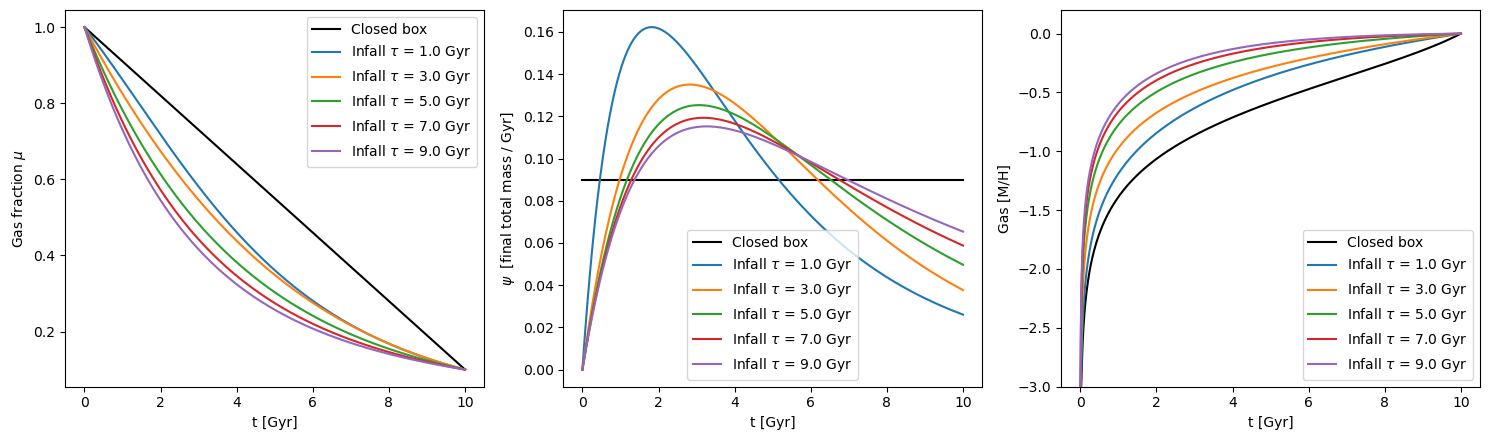

In [30]:
# Time evolution: gas fraction, SFR and gas metallicity
t_cb = np.linspace(0.0, T_MW, 500)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
axes[0].plot(t_cb, gas_fraction(t_cb), "k-", label="Closed box")
axes[1].plot(t_cb, np.full_like(t_cb, (1 - MU_F) / T_MW), "k-", label="Closed box")
axes[2].plot(t_cb, Z_to_MH(closed_box(t_cb)), "k-", label="Closed box")

for tau, m in models.items():
    lab = rf"Infall $\tau$ = {tau} Gyr"
    axes[0].plot(m["t"], m["mu"], label=lab)
    axes[1].plot(m["t"], m["psi"], label=lab)
    axes[2].plot(m["t"], Z_to_MH(m["Z"]), label=lab)

axes[0].set_ylabel(r"Gas fraction $\mu$")
axes[1].set_ylabel(r"$\psi$  [final total mass / Gyr]")
axes[2].set_ylabel("Gas [M/H]")
axes[2].set_ylim(MH_FLOOR, 0.2)
for ax in axes:
    ax.set_xlabel("t [Gyr]")
    ax.legend()
fig.tight_layout()
fig.savefig("figs/infall_evolution.png", dpi=150)
plt.show()

In [31]:
def sample_birth_times_from_sfr(model, n, rng):
    """
    Draws birth times with probability proportional to psi(t) (numerical inverse transform).
    Inputs: model, dict with arrays t and psi; n, number of stars; rng, np.random.Generator
    Output: array (n,) of t_birth in Gyr
    """
    t, psi = model["t"], model["psi"]
    cdf = np.concatenate(([0.0], np.cumsum(0.5 * (psi[1:] + psi[:-1]) * np.diff(t))))
    cdf /= cdf[-1]
    return np.interp(rng.uniform(size=n), cdf, t)

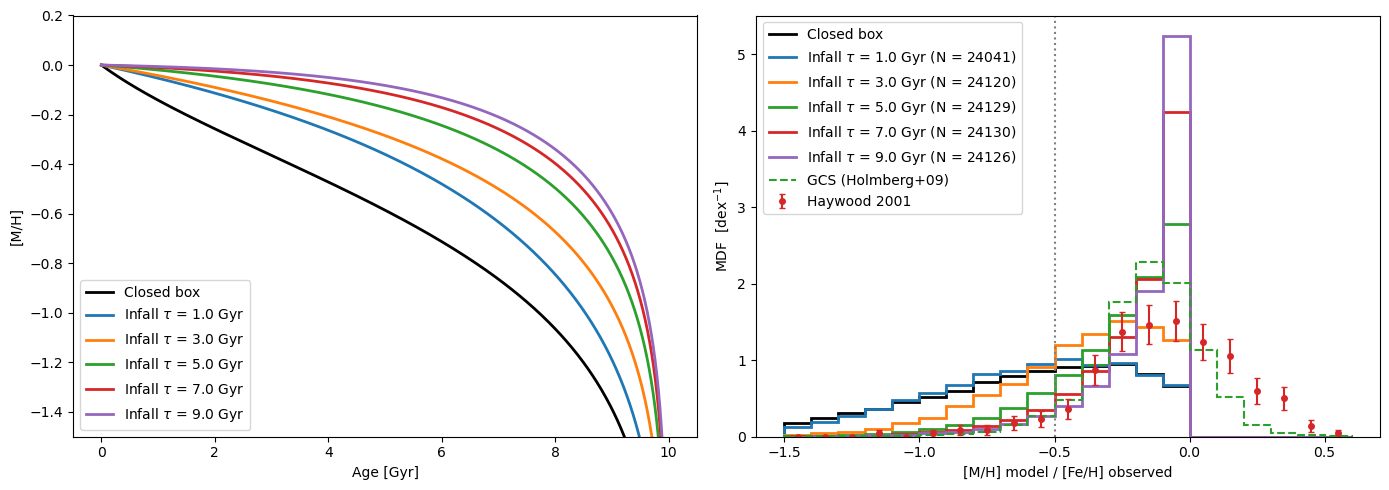

In [32]:
# Infall population: same masses M, new t_birth drawn from psi(t)
infall_pop = {}
for tau, m in models.items():
    tb = sample_birth_times_from_sfr(m, N, rng)
    MH_inf = Z_to_MH(np.interp(tb, m["t"], m["Z"]))
    is_MS_inf = (M >= M_H_BURN) & (T_MW - tb <= t_MS)
    is_G_inf = is_MS_inf & (M > G_MIN) & (M < G_MAX)
    infall_pop[tau] = dict(t_birth=tb, MH=MH_inf, MH_G=MH_inf[is_G_inf])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Age-metallicity relation (gas curves)
axes[0].plot(T_MW - t_cb, Z_to_MH(closed_box(t_cb)), "k-", lw=2, label="Closed box")
for tau, m in models.items():
    axes[0].plot(T_MW - m["t"], Z_to_MH(m["Z"]), lw=2, label=rf"Infall $\tau$ = {tau} Gyr")
axes[0].set_xlabel("Age [Gyr]")
axes[0].set_ylabel("[M/H]")
axes[0].set_ylim(-1.5, 0.2)
axes[0].legend()

# G-dwarf MDF
axes[1].stairs(pdf_mod, bins_feh, lw=2, color="k", label="Closed box")
for tau, pop in infall_pop.items():
    pdf_inf, _, n_inf = mdf(pop["MH_G"], bins_feh)
    axes[1].stairs(pdf_inf, bins_feh, lw=2, label=rf"Infall $\tau$ = {tau} Gyr (N = {n_inf})")
axes[1].stairs(pdf_gcs, bins_feh, lw=1.5, ls="--", color="C2", label="GCS (Holmberg+09)")
axes[1].errorbar(centers, pdf_hay, yerr=err_hay, fmt="o", ms=4, color="C3", capsize=2, label="Haywood 2001")
axes[1].axvline(MH_CUT, ls=":", c="gray")
axes[1].set_xlabel("[M/H] model / [Fe/H] observed")
axes[1].set_ylabel(r"MDF  [dex$^{-1}$]")
axes[1].legend()

fig.tight_layout()
fig.savefig("figs/mdf_infall_vs_obs.png", dpi=150)
plt.show()

In [33]:
# Metal-poor fraction, peak and median of each model and of the observations
print(f"{'Model':<20}{'N':>7}   {'f([M/H] < -0.5)':<18}{'Peak':>7}{'Median':>9}")
rows = [("Closed box", MH_G)] \
     + [(f"Infall tau = {tau}", pop["MH_G"]) for tau, pop in infall_pop.items()] \
     + [("Haywood", feh_hay), ("GCS", feh_gcs)]
for name, vals in rows:
    pdf_x, _, _ = mdf(vals, bins_feh)
    print(f"{name:<20}{len(vals):>7}   {frac_below(vals, MH_CUT):.3f} ± {binomial_error(vals, MH_CUT):.3f}"
          f"   {centers[np.argmax(pdf_x)]:>7.2f}{np.median(vals):>9.2f}")

Model                     N   f([M/H] < -0.5)      Peak   Median
Closed box            24003   0.573 ± 0.003     -0.25    -0.58
Infall tau = 1.0      24041   0.561 ± 0.003     -0.45    -0.56
Infall tau = 3.0      24120   0.326 ± 0.003     -0.25    -0.36
Infall tau = 5.0      24129   0.160 ± 0.002     -0.05    -0.21
Infall tau = 7.0      24130   0.096 ± 0.002     -0.05    -0.13
Infall tau = 9.0      24126   0.071 ± 0.002     -0.05    -0.09
Haywood                 218   0.069 ± 0.017     -0.05    -0.09
GCS                   16394   0.060 ± 0.002     -0.15    -0.14


###  Part 8: Convergence

In [34]:
def simulate(N, seed):
    """
    Runs the full simulation (IMF, constant SFR, classification and remnants) for N objects.
    Inputs: N, number of objects; seed, generator seed
    Output: dict with N, n_stars (M >= 0.08) and fractions f_BD (of all objects) and
            f_MS, f_WD, f_NS, f_BH (of stars)
    """
    rng_sim = np.random.default_rng(seed)
    M_sim = sample_kroupa(N, rng_sim)
    t_age_sim = T_MW - sample_birth_times(N, rng_sim)
    rtype, _ = classify_population(M_sim, t_age_sim, rng_sim)

    n_st = np.sum(rtype != BD)
    out = dict(N=N, n_stars=n_st, f_BD=np.mean(rtype == BD))
    for c in [MS, WD, NS, BH]:
        out[f"f_{TYPE_NAMES[c]}"] = np.sum(rtype == c) / n_st if n_st > 0 else np.nan
    return out

In [35]:
conv_types = ["MS", "WD", "NS", "BH"]
conv_mean = {c: [] for c in conv_types}
conv_std = {c: [] for c in conv_types}
n_stars_mean = []

for N_i in N_CONV:
    runs = [simulate(N_i, seed + j) for j in range(1, N_SEEDS + 1)]
    n_stars_mean.append(np.mean([r["n_stars"] for r in runs]))
    for c in conv_types:
        vals = np.array([r[f"f_{c}"] for r in runs])
        conv_mean[c].append(vals.mean())
        conv_std[c].append(vals.std(ddof=1))

conv_mean = {c: np.array(v) for c, v in conv_mean.items()}
conv_std = {c: np.array(v) for c, v in conv_std.items()}
n_stars_mean = np.array(n_stars_mean)

print(f"{'N':>9}" + "".join(f"{'f_' + c:>20}" for c in conv_types))
for i, N_i in enumerate(N_CONV):
    print(f"{N_i:>9}" + "".join(f"{conv_mean[c][i]:>12.5f} ±{conv_std[c][i]:>7.5f}" for c in conv_types))

        N                f_MS                f_WD                f_NS                f_BH
      100     0.93951 ±0.03212     0.05429 ±0.02835     0.00467 ±0.00752     0.00154 ±0.00487
      316     0.93634 ±0.01505     0.05967 ±0.01430     0.00247 ±0.00345     0.00152 ±0.00345
     1000     0.94299 ±0.01050     0.05271 ±0.00925     0.00303 ±0.00204     0.00128 ±0.00182
     3162     0.93829 ±0.00587     0.05687 ±0.00644     0.00357 ±0.00107     0.00126 ±0.00086
    10000     0.93687 ±0.00319     0.05795 ±0.00351     0.00357 ±0.00092     0.00160 ±0.00033
    31622     0.93698 ±0.00147     0.05779 ±0.00158     0.00358 ±0.00056     0.00165 ±0.00018
   100000     0.93650 ±0.00092     0.05824 ±0.00093     0.00347 ±0.00022     0.00180 ±0.00018
   316227     0.93646 ±0.00035     0.05821 ±0.00040     0.00355 ±0.00013     0.00178 ±0.00011
  1000000     0.93631 ±0.00027     0.05835 ±0.00032     0.00359 ±0.00007     0.00175 ±0.00005


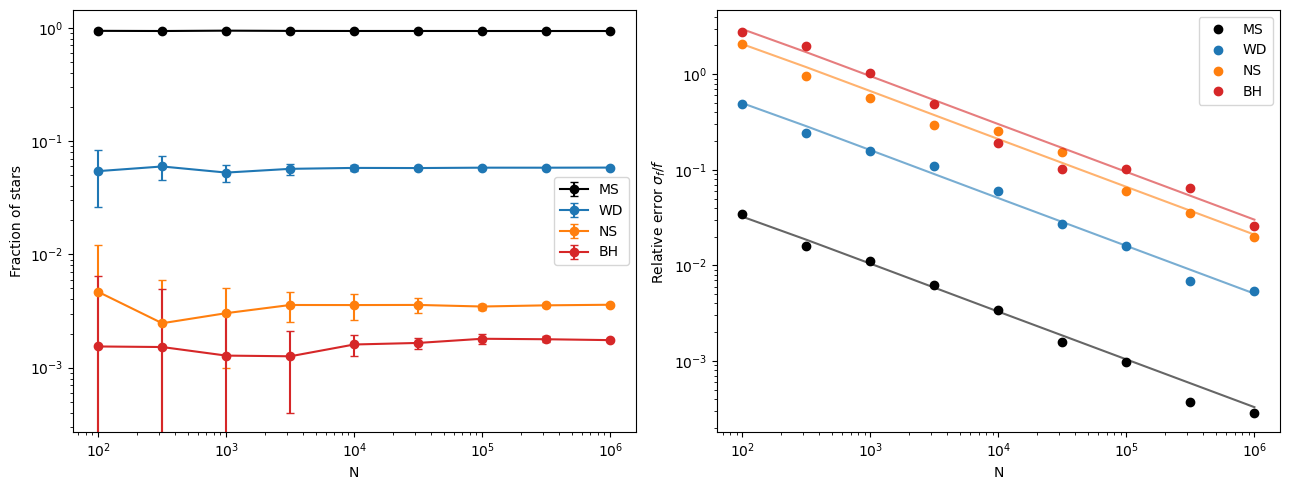

In [36]:
# Left: mean fraction ± scatter between seeds
# Right: relative error of the simulation (points) vs binomial prediction (lines)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for c, col in zip(conv_types, ["k", "C0", "C1", "C3"]):
    f_ref = conv_mean[c][-1]                                   # best estimate (N = 1e6)
    axes[0].errorbar(N_CONV, conv_mean[c], yerr=conv_std[c], fmt="o-", color=col, capsize=3, label=c)
    axes[1].plot(N_CONV, conv_std[c] / f_ref, "o", color=col, label=c)
    axes[1].plot(N_CONV, np.sqrt((1 - f_ref) / (f_ref * n_stars_mean)), "-", color=col, alpha=0.6)

for ax in axes:
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("N")
    ax.legend()
axes[0].set_ylabel("Fraction of stars")
axes[1].set_ylabel(r"Relative error $\sigma_f / f$")
fig.tight_layout()
fig.savefig("figs/convergence.png", dpi=150)
plt.show()